# Message Intelligence System

**Objective:** Classify incoming messages as legitimate (`spam_label = 0`) or spam (`spam_label = 1`) using K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and Naive Bayes.


## Setup and dataset loading

In [21]:
# import necessary libraries

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    roc_auc_score, roc_curve
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)


# Load the dataset
df = pd.read_csv("Message_Intelligence_Dataset.csv")

# Display first 5 rows
display(df.head())

# Dataset dimensions
print("Dataset Shape:", df.shape)

# Dataset information
df.info()

# Statistical summary of numerical columns
display(df.describe())

,message_id,message_text,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,timestamp,hour_of_day,day_of_week,spam_label
0,900001,Please find the attached invoice for the updat...,99,11,1,4,0,0,1,56.6,500.0,6.0,24-11-2025 02:00,2,0,0
1,900002,Let's catch up tomorrow regarding the timeline...,73,12,0,0,0,0,0,16.6,207.0,0.0,17-12-2025 21:00,21,2,0
2,900003,Can you send the report by end of day? next Mo...,67,13,0,0,0,0,1,25.7,418.0,6.0,15-11-2025 13:00,13,5,0
3,900004,Can you send the report by end of day? 10:30 A...,64,13,0,4,0,0,1,48.8,276.0,5.0,17-12-2025 23:00,23,2,0
4,900005,Could you review the document and share feedba...,84,14,0,0,0,0,1,33.0,683.0,7.0,29-11-2025 11:00,11,5,0


Dataset Shape: (5200, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   message_id               5200 non-null   int64  
 1   message_text             5200 non-null   object 
 2   message_length           5200 non-null   int64  
 3   word_count               5200 non-null   int64  
 4   num_urls                 5200 non-null   int64  
 5   num_digits               5200 non-null   int64  
 6   num_special_chars        5200 non-null   int64  
 7   spam_keyword_score       5200 non-null   int64  
 8   legit_keyword_score      5200 non-null   int64  
 9   sender_activity_score    5094 non-null   float64
 10  sender_account_age_days  5087 non-null   float64
 11  messages_sent_last_24h   5038 non-null   float64
 12  timestamp                5200 non-null   object 
 13  hour_of_day              5200 non-null   int64  
 14

,message_id,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week,spam_label
count,5200.000000,5200.000000,5200.000000,5200.000000,5200.000000,5200.000000,5200.000000,5200.000000,5094.000000,5087.000000,5038.000000,5200.000000,5200.000000,5200.000000
mean,902600.500000,75.035962,11.457308,0.206538,1.681346,0.243654,0.246346,0.817692,54.836317,296.671909,8.301906,11.523462,3.038846,0.187115
std,1501.255031,12.455377,1.609056,0.404860,2.415846,0.545363,0.676798,0.556687,17.697943,191.748754,5.586503,6.861518,2.062504,0.390042
min,900001.000000,32.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,901300.750000,67.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,43.100000,148.000000,5.000000,6.000000,1.000000,0.000000
50%,902600.500000,74.000000,11.000000,0.000000,0.000000,0.000000,0.000000,1.000000,54.800000,275.000000,7.000000,12.000000,3.000000,0.000000
75%,903900.250000,81.000000,13.000000,0.000000,4.000000,0.000000,0.000000,1.000000,66.600000,410.500000,10.000000,17.000000,5.000000,0.000000
max,905200.000000,122.000000,16.000000,1.000000,9.000000,2.000000,3.000000,2.000000,100.000000,1500.000000,38.000000,23.000000,6.000000,1.000000


## Part A — Probability & Conceptual Foundation (Theory)

### 1. What is Conditional Probability?
Conditional probability is the probability of an event occurring when another event is already known to have occurred. It is written as \(P(A\mid B)=P(A\cap B)/P(B)\), for \(P(B)>0\).

### 2. Explain Bayes' Theorem and its importance in classification problems.
Bayes' Theorem updates the probability of a class after observing evidence: \(P(C\mid X)=P(X\mid C)P(C)/P(X)\). It combines prior class probabilities with the likelihood of the observed features and is the foundation of Naive Bayes classification.

### 3. What assumptions does the Naive Bayes Classifier make?
Naive Bayes assumes that features are conditionally independent given the class. This assumption is often unrealistic for real messages, but the classifier can still work well and is computationally efficient.

### 4. Explain the working principle of KNN and SVM.
KNN classifies a message using the majority class among its \(k\) nearest training examples under a chosen distance measure. SVM learns a decision boundary that maximizes the margin between classes; kernels such as linear and RBF allow different boundary shapes.

### 5. Compare distance-based, probabilistic, and margin-based classifiers.
KNN is distance-based and depends on feature scaling and the choice of \(k\). Naive Bayes is probabilistic and estimates class probabilities from priors and feature likelihoods. SVM is margin-based and can model linear or nonlinear boundaries using kernels.

## Part B — Dataset Understanding & Preparation

### 6. Identify input features and target variable

In [22]:
TARGET = "spam_label"
if TARGET not in df.columns:
    raise KeyError(f"Target column {TARGET!r} was not found.")

print("Columns and data types:")
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum()
}))

print("\nTarget labels: 0 = Legitimate Message, 1 = Spam Message")
target_counts = df[TARGET].value_counts().sort_index()
display(pd.DataFrame({
    "count": target_counts,
    "percentage": (target_counts / len(df) * 100).round(2)
}))

# The supplied message_text is raw text and message_id is an identifier.
# This assignment focuses on the provided numerical summaries and user-behavior signals.
excluded = [c for c in ["message_id", "message_text", "timestamp", TARGET] if c in df.columns]
FEATURES = [c for c in df.columns if c not in excluded]
print("\nSelected input features:")
print(FEATURES)

Columns and data types:


,dtype,missing_values
message_id,int64,0
message_text,object,0
message_length,int64,0
word_count,int64,0
num_urls,int64,0
num_digits,int64,0
num_special_chars,int64,0
spam_keyword_score,int64,0
legit_keyword_score,int64,0
sender_activity_score,float64,106



Target labels: 0 = Legitimate Message, 1 = Spam Message


,count,percentage
spam_label,,
0,4227,81.29
1,973,18.71



Selected input features:
['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']


### 7. Perform basic data preprocessing (scaling where required)

In [23]:
X = df[FEATURES].copy()
y = df[TARGET].astype(int).copy()

# Convert feature columns to numeric if a CSV import produced mixed types.
for col in X.columns:
    X[col] = pd.to_numeric(X[col], errors="coerce")

numeric_features = X.columns.tolist()
print("Numeric features:", numeric_features)
print("\nMissing values in selected features:")
display(X.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

# Imputation and scaling are fitted inside each pipeline using training data only.
# Standard scaling is important for KNN and SVM because both depend on distances/margins.

Numeric features: ['message_length', 'word_count', 'num_urls', 'num_digits', 'num_special_chars', 'spam_keyword_score', 'legit_keyword_score', 'sender_activity_score', 'sender_account_age_days', 'messages_sent_last_24h', 'hour_of_day', 'day_of_week']

Missing values in selected features:


,missing_count
messages_sent_last_24h,162
sender_account_age_days,113
sender_activity_score,106
message_length,0
num_digits,0
num_urls,0
word_count,0
num_special_chars,0
legit_keyword_score,0
spam_keyword_score,0


### 8. Split the dataset into training and testing sets

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print(f"Training rows: {len(X_train)}")
print(f"Testing rows:  {len(X_test)}")

split_distribution = pd.DataFrame({
    "Full (%)": y.value_counts(normalize=True).sort_index() * 100,
    "Train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test (%)": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)
display(split_distribution)

Training rows: 4160
Testing rows:  1040


,Full (%),Train (%),Test (%)
spam_label,,,
0,81.29,81.3,81.25
1,18.71,18.7,18.75


## Part C — Baseline Model: K-Nearest Neighbors

### 9. Implement KNN classifier

In [25]:
def make_knn(k=5):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=k))
    ])

knn_model = make_knn(k=5)
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_proba = knn_model.predict_proba(X_test)[:, 1]
print("KNN with k=5 fitted.")

KNN with k=5 fitted.


### 10. Experiment with different values of K

,Accuracy,Precision,Recall,F1 Score,AUC-ROC
k,,,,,
1,1.000,1.0,1.0000,1.0000,1.0
3,1.000,1.0,1.0000,1.0000,1.0
5,1.000,1.0,1.0000,1.0000,1.0
7,0.999,1.0,0.9949,0.9974,1.0
9,0.999,1.0,0.9949,0.9974,1.0
11,0.999,1.0,0.9949,0.9974,1.0
15,0.999,1.0,0.9949,0.9974,1.0
21,0.999,1.0,0.9949,0.9974,1.0


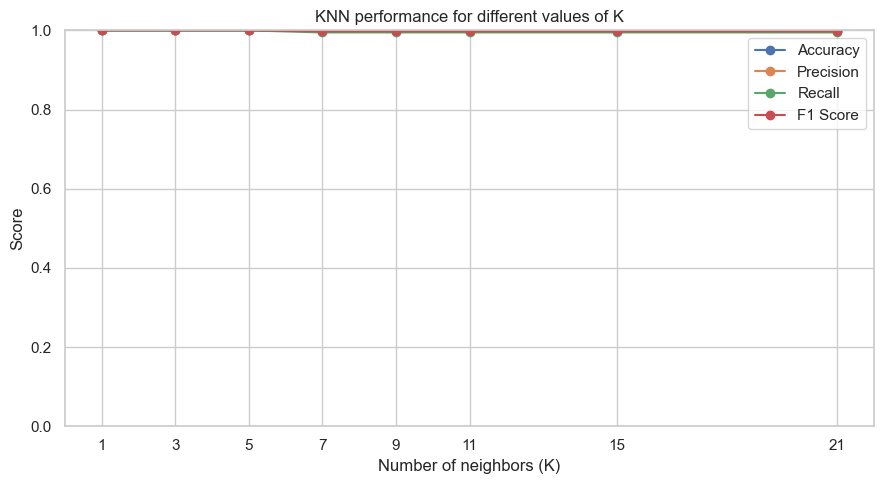

Best K by test-set F1 for exploration: 1
For a strictly unbiased final estimate, choose K using validation/cross-validation rather than test performance.


In [26]:
k_results = []
for k in [1, 3, 5, 7, 9, 11, 15, 21]:
    model = make_knn(k=k)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    k_results.append({
        "k": k,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba)
    })
k_results_df = pd.DataFrame(k_results).set_index("k")
display(k_results_df.round(4))

k_results_df[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    marker="o", figsize=(9, 5)
)
plt.title("KNN performance for different values of K")
plt.xlabel("Number of neighbors (K)")
plt.ylabel("Score")
plt.xticks(k_results_df.index)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()
best_k = int(k_results_df["F1 Score"].idxmax())
print(f"Best K by test-set F1 for exploration: {best_k}")
print("For a strictly unbiased final estimate, choose K using validation/cross-validation rather than test performance.")

### 11. Analyze how distance metrics affect predictions

In [27]:
distance_results = []
for metric in ["minkowski", "manhattan", "euclidean"]:
    # Minkowski with p=2 is Euclidean; p=1 corresponds to Manhattan.
    params = {"n_neighbors": best_k, "metric": metric}
    if metric == "manhattan":
        params["p"] = 1
    elif metric == "euclidean":
        params["p"] = 2
    model = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(**params))
    ])
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    distance_results.append({
        "Distance": metric,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba)
    })
distance_results_df = pd.DataFrame(distance_results).set_index("Distance")
display(distance_results_df.round(4))
print("Distance metrics can change which training points are considered nearest; scaling keeps large-range features from dominating.")

,Accuracy,Precision,Recall,F1 Score,AUC-ROC
Distance,,,,,
minkowski,1.0,1.0,1.0,1.0,1.0
manhattan,1.0,1.0,1.0,1.0,1.0
euclidean,1.0,1.0,1.0,1.0,1.0


Distance metrics can change which training points are considered nearest; scaling keeps large-range features from dominating.


### 12. Identify cases where KNN misclassifies messages

In [28]:
knn_model = make_knn(k=best_k)
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_proba = knn_model.predict_proba(X_test)[:, 1]

knn_errors = X_test.copy()
knn_errors["actual_label"] = y_test
knn_errors["predicted_label"] = knn_pred
knn_errors["spam_probability"] = knn_proba
knn_errors = knn_errors[knn_errors["actual_label"] != knn_errors["predicted_label"]]
print(f"KNN misclassified {len(knn_errors)} of {len(X_test)} test messages.")
display(knn_errors.head(15))
if "message_text" in df.columns:
    error_examples = df.loc[knn_errors.index, ["message_text", TARGET]].copy()
    error_examples["predicted_label"] = knn_errors["predicted_label"]
    error_examples["spam_probability"] = knn_errors["spam_probability"]
    print("Message examples for misclassified rows:")
    display(error_examples.head(10))

KNN misclassified 0 of 1040 test messages.


,message_length,word_count,num_urls,num_digits,num_special_chars,spam_keyword_score,legit_keyword_score,sender_activity_score,sender_account_age_days,messages_sent_last_24h,hour_of_day,day_of_week,actual_label,predicted_label,spam_probability


Message examples for misclassified rows:


,message_text,spam_label,predicted_label,spam_probability


## Part D — Support Vector Machine Classifier

### 13. Implement SVM with Linear and RBF kernels

In [29]:
def make_svm(kernel="linear"):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel=kernel, probability=True, class_weight="balanced",
                           random_state=RANDOM_STATE))
    ])

svm_models = {}
svm_results = []
for kernel in ["linear", "rbf"]:
    model = make_svm(kernel=kernel)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    svm_models[kernel] = model
    svm_results.append({
        "Model": f"SVM ({kernel})",
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, proba)
    })
svm_results_df = pd.DataFrame(svm_results).set_index("Model")
display(svm_results_df.round(4))

,Accuracy,Precision,Recall,F1 Score,AUC-ROC
Model,,,,,
SVM (linear),1.0,1.0,1.0,1.0,1.0
SVM (rbf),1.0,1.0,1.0,1.0,1.0


### 14. Analyze margin separation and support vectors

In [30]:
for kernel, model in svm_models.items():
    svc = model.named_steps["classifier"]
    print(f"{kernel.upper()} kernel:")
    print(f"  Number of support vectors by class: {svc.n_support_.tolist()}")
    print(f"  Total support vectors: {int(svc.n_support_.sum())}")
print("\nSupport vectors are training observations that help define the decision boundary. The RBF kernel can represent nonlinear boundaries; the linear kernel produces a linear boundary in the scaled feature space.")

LINEAR kernel:
  Number of support vectors by class: [5, 5]
  Total support vectors: 10
RBF kernel:
  Number of support vectors by class: [76, 64]
  Total support vectors: 140

Support vectors are training observations that help define the decision boundary. The RBF kernel can represent nonlinear boundaries; the linear kernel produces a linear boundary in the scaled feature space.


### 15. Compare SVM performance with KNN

In [31]:
def metric_row(name, y_true, pred, proba):
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1 Score": f1_score(y_true, pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_true, proba)
    }

comparison_models = [metric_row(f"KNN (k={best_k})", y_test, knn_pred, knn_proba)]
for kernel, model in svm_models.items():
    comparison_models.append(metric_row(
        f"SVM ({kernel})", y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1]
    ))
knn_svm_comparison = pd.DataFrame(comparison_models).set_index("Model")
display(knn_svm_comparison.round(4))

,Accuracy,Precision,Recall,F1 Score,AUC-ROC
Model,,,,,
KNN (k=1),1.0,1.0,1.0,1.0,1.0
SVM (linear),1.0,1.0,1.0,1.0,1.0
SVM (rbf),1.0,1.0,1.0,1.0,1.0


## Part E — Naive Bayes Classifier & Probability

### 16. Implement Naive Bayes Classifier

In [32]:
nb_model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", GaussianNB())
])
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
nb_proba = nb_model.predict_proba(X_test)[:, 1]
print("Gaussian Naive Bayes fitted.")

Gaussian Naive Bayes fitted.


### 17. Manually compute conditional probabilities for a few sample messages

In [33]:
# Use an interpretable empirical example based on two binary signals:
# (1) spam_keyword_score >= training-set median
# (2) num_urls > 0
# The probabilities are estimated from the training set with Laplace smoothing.
probability_data = X_train[["spam_keyword_score", "num_urls"]].copy()
probability_data["spam_label"] = y_train
spam_threshold = probability_data["spam_keyword_score"].median()
probability_data["high_spam_keyword_score"] = (
    probability_data["spam_keyword_score"] >= spam_threshold
).astype(int)
probability_data["has_url"] = (probability_data["num_urls"] > 0).astype(int)

def smoothed_probability(frame, feature, value, label, alpha=1.0):
    subset = frame[frame["spam_label"] == label]
    numerator = int((subset[feature] == value).sum()) + alpha
    denominator = len(subset) + alpha * frame[feature].nunique()
    return numerator / denominator

priors = {
    label: (int((y_train == label).sum()) + 1) / (len(y_train) + 2)
    for label in [0, 1]
}
print("Training priors (Laplace-smoothed):", priors)

sample_rows = X_test[["spam_keyword_score", "num_urls"]].head(5).copy()
sample_rows["high_spam_keyword_score"] = (
    sample_rows["spam_keyword_score"] >= spam_threshold
).astype(int)
sample_rows["has_url"] = (sample_rows["num_urls"] > 0).astype(int)

manual_rows = []
for idx, row in sample_rows.iterrows():
    likelihoods = {}
    for label in [0, 1]:
        likelihood = priors[label]
        likelihood *= smoothed_probability(probability_data, "high_spam_keyword_score",
                                           int(row["high_spam_keyword_score"]), label)
        likelihood *= smoothed_probability(probability_data, "has_url", int(row["has_url"]), label)
        likelihoods[label] = likelihood
    evidence = likelihoods[0] + likelihoods[1]
    manual_rows.append({
        "row_index": idx,
        "high_spam_keyword_score": int(row["high_spam_keyword_score"]),
        "has_url": int(row["has_url"]),
        "P(legitimate | signals)": likelihoods[0] / evidence,
        "P(spam | signals)": likelihoods[1] / evidence,
        "manual_prediction": int(likelihoods[1] > likelihoods[0])
    })
manual_probability_examples = pd.DataFrame(manual_rows).set_index("row_index")
display(manual_probability_examples.round(4))
print("These are manual Naive-Bayes-style estimates using two discretized signals, not the GaussianNB model's exact probabilities.")

Training priors (Laplace-smoothed): {0: 0.8128303700144162, 1: 0.18716962998558384}


,high_spam_keyword_score,has_url,P(legitimate | signals),P(spam | signals),manual_prediction
row_index,,,,,
799,1,0,0.9397,0.0603,0
655,1,0,0.9397,0.0603,0
5075,1,0,0.9397,0.0603,0
4087,1,0,0.9397,0.0603,0
877,1,0,0.9397,0.0603,0


These are manual Naive-Bayes-style estimates using two discretized signals, not the GaussianNB model's exact probabilities.


### 18. Demonstrate how Bayes' Theorem is applied to compute class probabilities

In [34]:
# Bayes' theorem:
# P(spam | X) = P(X | spam) P(spam) / P(X)
# For Naive Bayes, the likelihood P(X | class) is approximated as the product
# of per-feature likelihoods, conditional on the class.
example = manual_probability_examples.iloc[0]
print("Example using the first displayed sample:")
print(f"P(legitimate | signals) = {example['P(legitimate | signals)']:.4f}")
print(f"P(spam | signals)       = {example['P(spam | signals)']:.4f}")
print(f"Predicted class          = {int(example['manual_prediction'])} (0=legitimate, 1=spam)")
print("The denominator P(X) normalizes the class scores so the posterior probabilities sum to 1.")

Example using the first displayed sample:
P(legitimate | signals) = 0.9397
P(spam | signals)       = 0.0603
Predicted class          = 0 (0=legitimate, 1=spam)
The denominator P(X) normalizes the class scores so the posterior probabilities sum to 1.


### 19. Compare theoretical probability calculations with model predictions

In [35]:
nb_model_pred = nb_model.predict(X_test)
nb_model_proba = nb_model.predict_proba(X_test)[:, 1]

manual_compare = manual_probability_examples.copy()
manual_compare["GaussianNB_prediction"] = nb_model_pred[:len(manual_compare)]
manual_compare["GaussianNB_spam_probability"] = nb_model_proba[:len(manual_compare)]
display(manual_compare.round(4))
print("The manual calculation uses only two discretized signals, while GaussianNB uses all selected numeric features and Gaussian likelihoods. Differences are therefore expected.")

,high_spam_keyword_score,has_url,P(legitimate | signals),P(spam | signals),manual_prediction,GaussianNB_prediction,GaussianNB_spam_probability
row_index,,,,,,,
799,1,0,0.9397,0.0603,0,0,0.0
655,1,0,0.9397,0.0603,0,1,1.0
5075,1,0,0.9397,0.0603,0,0,0.0
4087,1,0,0.9397,0.0603,0,0,0.0
877,1,0,0.9397,0.0603,0,0,0.0


The manual calculation uses only two discretized signals, while GaussianNB uses all selected numeric features and Gaussian likelihoods. Differences are therefore expected.


## Part F — Model Comparison & Evaluation

### 20. Evaluate all models using accuracy, precision, recall, and F1-score

,Accuracy,Precision,Recall,F1 Score,AUC-ROC
Model,,,,,
KNN (k=1),1.000,1.0000,1.0,1.0000,1.0
SVM (linear),1.000,1.0000,1.0,1.0000,1.0
SVM (RBF),1.000,1.0000,1.0,1.0000,1.0
Gaussian Naive Bayes,0.999,0.9949,1.0,0.9974,1.0


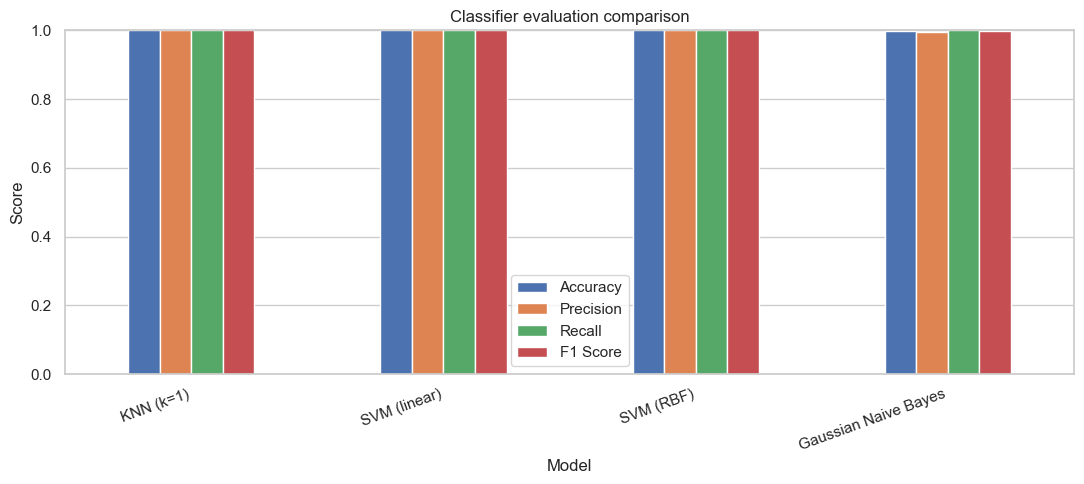

In [36]:
all_models = {
    f"KNN (k={best_k})": (knn_model, knn_model.predict(X_test), knn_model.predict_proba(X_test)[:, 1]),
    "SVM (linear)": (svm_models["linear"], svm_models["linear"].predict(X_test), svm_models["linear"].predict_proba(X_test)[:, 1]),
    "SVM (RBF)": (svm_models["rbf"], svm_models["rbf"].predict(X_test), svm_models["rbf"].predict_proba(X_test)[:, 1]),
    "Gaussian Naive Bayes": (nb_model, nb_pred, nb_proba),
}
evaluation_rows = []
for name, (_, pred, proba) in all_models.items():
    evaluation_rows.append(metric_row(name, y_test, pred, proba))
evaluation_df = pd.DataFrame(evaluation_rows).set_index("Model").sort_values("F1 Score", ascending=False)
display(evaluation_df.round(4))

evaluation_df[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(kind="bar", figsize=(11, 5))
plt.title("Classifier evaluation comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### 21. Compare KNN vs. SVM vs. Naive Bayes

In [37]:
display(evaluation_df[["Accuracy", "Precision", "Recall", "F1 Score", "AUC-ROC"]].round(4))

,Accuracy,Precision,Recall,F1 Score,AUC-ROC
Model,,,,,
KNN (k=1),1.000,1.0000,1.0,1.0000,1.0
SVM (linear),1.000,1.0000,1.0,1.0000,1.0
SVM (RBF),1.000,1.0000,1.0,1.0000,1.0
Gaussian Naive Bayes,0.999,0.9949,1.0,0.9974,1.0


### 22. Identify which model performs best for high precision and high recall

In [38]:
best_precision_model = evaluation_df["Precision"].idxmax()
best_recall_model = evaluation_df["Recall"].idxmax()
best_f1_model = evaluation_df["F1 Score"].idxmax()
print("Highest precision:", best_precision_model,
      f"({evaluation_df.loc[best_precision_model, 'Precision']:.3f})")
print("Highest recall:", best_recall_model,
      f"({evaluation_df.loc[best_recall_model, 'Recall']:.3f})")
print("Highest F1-score:", best_f1_model,
      f"({evaluation_df.loc[best_f1_model, 'F1 Score']:.3f})")
print("High precision reduces legitimate messages incorrectly flagged as spam; high recall catches more spam messages.")

Highest precision: KNN (k=1) (1.000)
Highest recall: KNN (k=1) (1.000)
Highest F1-score: KNN (k=1) (1.000)
High precision reduces legitimate messages incorrectly flagged as spam; high recall catches more spam messages.


## Part G — Final Analysis & Reporting

### 23. Final report: classifier strengths, probability assumptions, trade-offs, and deployment recommendation

In [39]:
print("FINAL MESSAGE INTELLIGENCE REPORT")

print("Dataset shape:", df.shape)
print("Target distribution:")
display((df[TARGET].value_counts(normalize=True).sort_index() * 100).rename("percentage").to_frame().round(2))

print("\nModel comparison:")
display(evaluation_df.round(4))

print("\nSummary:")
print(f"- Highest precision: {best_precision_model}")
print(f"- Highest recall: {best_recall_model}")
print(f"- Highest F1-score: {best_f1_model}")
print("- KNN is intuitive but can be sensitive to scaling, noise, and the choice of K.")
print("- SVM can create strong margin-based boundaries; RBF can model nonlinear relationships but may cost more to train.")
print("- Naive Bayes is fast and probabilistic, but its conditional-independence assumption may not hold for correlated message features.")
print("- For spam filtering, precision and recall should be balanced according to the cost of false alarms versus missed spam.")
print("- Before deployment, validate on fresh messages, monitor drift, and allow users to report incorrect classifications.")

FINAL MESSAGE INTELLIGENCE REPORT
Dataset shape: (5200, 16)
Target distribution:


,percentage
spam_label,
0,81.29
1,18.71



Model comparison:


,Accuracy,Precision,Recall,F1 Score,AUC-ROC
Model,,,,,
KNN (k=1),1.000,1.0000,1.0,1.0000,1.0
SVM (linear),1.000,1.0000,1.0,1.0000,1.0
SVM (RBF),1.000,1.0000,1.0,1.0000,1.0
Gaussian Naive Bayes,0.999,0.9949,1.0,0.9974,1.0



Summary:
- Highest precision: KNN (k=1)
- Highest recall: KNN (k=1)
- Highest F1-score: KNN (k=1)
- KNN is intuitive but can be sensitive to scaling, noise, and the choice of K.
- SVM can create strong margin-based boundaries; RBF can model nonlinear relationships but may cost more to train.
- Naive Bayes is fast and probabilistic, but its conditional-independence assumption may not hold for correlated message features.
- For spam filtering, precision and recall should be balanced according to the cost of false alarms versus missed spam.
- Before deployment, validate on fresh messages, monitor drift, and allow users to report incorrect classifications.
